In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, random_split
import numpy as np


In [2]:
# Training transformations with medical data augmentation
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Evaluation transformations (no augmentation)
eval_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

print("Transforms defined successfully.")


Transforms defined successfully.


In [3]:
# Function to build the improved MobileNetV2 model
def build_improved_model(num_classes=4):
    weights = models.MobileNet_V2_Weights.DEFAULT
    model = models.mobilenet_v2(weights=weights)

    # Freeze feature extraction layers
    for param in model.features.parameters():
        param.requires_grad = False

    # Enhanced classifier head: 1280 -> 256 -> 4 with Dropout
    model.classifier = nn.Sequential(
        nn.Dropout(p=0.3),
        nn.Linear(1280, 256),
        nn.ReLU(),
        nn.Dropout(p=0.2),
        nn.Linear(256, num_classes)
    )
    return model

sample_model = build_improved_model()
trainable = sum(p.numel() for p in sample_model.parameters() if p.requires_grad)
print(f"Improved model created. Trainable parameters: {trainable:,}")


Improved model created. Trainable parameters: 328,964


In [4]:
# Base datasets referencing the folders
train_dataset = datasets.ImageFolder(root="data", transform=train_transforms)
eval_dataset = datasets.ImageFolder(root="data", transform=eval_transforms)

train_size = int(0.70 * len(train_dataset))
val_size = int(0.15 * len(train_dataset))
test_size = len(train_dataset) - train_size - val_size

def get_loaders(seed, batch_size=32):
    # Deterministic permutation based on the seed
    indices = torch.randperm(len(train_dataset), generator=torch.Generator().manual_seed(seed)).tolist()
    
    train_idx = indices[:train_size]
    val_idx = indices[train_size:train_size + val_size]
    test_idx = indices[train_size + val_size:]
    
    train_set = torch.utils.data.Subset(train_dataset, train_idx)
    val_set = torch.utils.data.Subset(eval_dataset, val_idx)
    test_set = torch.utils.data.Subset(eval_dataset, test_idx)
    
    train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_set, batch_size=batch_size, shuffle=False)
    test_loader = DataLoader(test_set, batch_size=batch_size, shuffle=False)
    
    return train_loader, val_loader, test_loader

print(f"Data loader generator ready for any seed. Split: {train_size} train, {val_size} val, {test_size} test")


Data loader generator ready for any seed. Split: 2951 train, 632 val, 634 test


In [5]:
# Function to train and evaluate the improved model on a single seed
def train_and_evaluate_seed(seed, epochs=3):
    print(f"\n--- Running Experiment with Seed {seed} ---")
    torch.manual_seed(seed)
    
    train_loader, val_loader, test_loader = get_loaders(seed)
    model = build_improved_model()
    
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.classifier.parameters(), lr=0.001)
    
    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for images, labels in train_loader:
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
            
        train_loss = running_loss / total
        train_acc = (correct / total) * 100
        
        # Validation
        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for images, labels in val_loader:
                outputs = model(images)
                loss = criterion(outputs, labels)
                val_loss += loss.item() * images.size(0)
                _, preds = torch.max(outputs, 1)
                val_correct += (preds == labels).sum().item()
                val_total += labels.size(0)
                
        val_loss = val_loss / val_total
        val_acc = (val_correct / val_total) * 100
        print(f"Epoch {epoch+1}/{epochs} -> Train Loss: {train_loss:.4f}, Acc: {train_acc:.2f}% | Val Loss: {val_loss:.4f}, Acc: {val_acc:.2f}%")
        
    # Final Test evaluation
    model.eval()
    test_correct, test_total = 0, 0
    with torch.no_grad():
        for images, labels in test_loader:
            outputs = model(images)
            _, preds = torch.max(outputs, 1)
            test_correct += (preds == labels).sum().item()
            test_total += labels.size(0)
            
    final_acc = (test_correct / test_total) * 100
    print(f"Seed {seed} Test Accuracy: {final_acc:.2f}%")
    return final_acc

# Run first seed
acc_seed_42 = train_and_evaluate_seed(42, epochs=3)



--- Running Experiment with Seed 42 ---
Epoch 1/3 -> Train Loss: 0.7545, Acc: 70.42% | Val Loss: 0.5532, Acc: 75.16%
Epoch 2/3 -> Train Loss: 0.5887, Acc: 75.70% | Val Loss: 0.4595, Acc: 81.96%
Epoch 3/3 -> Train Loss: 0.5500, Acc: 78.41% | Val Loss: 0.4192, Acc: 84.49%
Seed 42 Test Accuracy: 83.91%


In [6]:
# Run remaining seeds and compute Mean ± Std
remaining_seeds = [123, 999]
all_accuracies = [acc_seed_42]

for s in remaining_seeds:
    acc = train_and_evaluate_seed(s, epochs=3)
    all_accuracies.append(acc)

mean_acc = np.mean(all_accuracies)
std_acc = np.std(all_accuracies)

print("\n=== Final 3-Seed Evaluation Summary ===")
for idx, s in enumerate([42, 123, 999]):
    print(f"Seed {s}: {all_accuracies[idx]:.2f}%")
print(f"Overall Test Accuracy: {mean_acc:.2f}% ± {std_acc:.2f}%")



--- Running Experiment with Seed 123 ---
Epoch 1/3 -> Train Loss: 0.7577, Acc: 68.62% | Val Loss: 0.4750, Acc: 83.86%
Epoch 2/3 -> Train Loss: 0.5717, Acc: 77.84% | Val Loss: 0.4248, Acc: 85.13%
Epoch 3/3 -> Train Loss: 0.5365, Acc: 79.36% | Val Loss: 0.4166, Acc: 85.13%
Seed 123 Test Accuracy: 81.23%

--- Running Experiment with Seed 999 ---
Epoch 1/3 -> Train Loss: 0.7428, Acc: 69.87% | Val Loss: 0.4862, Acc: 83.07%
Epoch 2/3 -> Train Loss: 0.5885, Acc: 77.53% | Val Loss: 0.4563, Acc: 84.49%
Epoch 3/3 -> Train Loss: 0.5839, Acc: 76.25% | Val Loss: 0.4325, Acc: 84.65%
Seed 999 Test Accuracy: 82.33%

=== Final 3-Seed Evaluation Summary ===
Seed 42: 83.91%
Seed 123: 81.23%
Seed 999: 82.33%
Overall Test Accuracy: 82.49% ± 1.10%


In [ ]:
# Setup Seed 42 data and model for Fine-Tuning
torch.manual_seed(42)
train_loader, val_loader, test_loader = get_loaders(42)

finetune_model = build_improved_model()

# Unfreeze the last two convolutional blocks of MobileNetV2
for param in finetune_model.features[17:].parameters():
    param.requires_grad = True

trainable_params = sum(p.numel() for p in finetune_model.parameters() if p.requires_grad)
print(f"Trainable parameters after unfreezing: {trainable_params:,}")


Fine-tuning mode activated.
Trainable parameters after unfreezing: 1,215,044


In [8]:
# Fine-tuning training loop with a small learning rate
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(filter(lambda p: p.requires_grad, finetune_model.parameters()), lr=1e-4)

epochs = 3

for epoch in range(epochs):
    # Training phase
    finetune_model.train()
    running_loss, correct, total = 0.0, 0, 0
    
    for images, labels in train_loader:
        optimizer.zero_grad()
        outputs = finetune_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
        
    train_loss = running_loss / total
    train_acc = (correct / total) * 100
    
    # Validation phase
    finetune_model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            outputs = finetune_model(images)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)
            
    val_loss = val_loss / val_total
    val_acc = (val_correct / val_total) * 100
    
    print(f"Fine-Tuning Epoch {epoch+1}/{epochs} -> Train Loss: {train_loss:.4f}, Acc: {train_acc:.2f}% | Val Loss: {val_loss:.4f}, Acc: {val_acc:.2f}%")


Fine-Tuning Epoch 1/3 -> Train Loss: 1.0015, Acc: 64.32% | Val Loss: 0.6196, Acc: 79.75%
Fine-Tuning Epoch 2/3 -> Train Loss: 0.6072, Acc: 76.28% | Val Loss: 0.4481, Acc: 83.07%
Fine-Tuning Epoch 3/3 -> Train Loss: 0.4821, Acc: 82.48% | Val Loss: 0.3978, Acc: 85.76%


In [9]:
# Continue fine-tuning for 2 additional epochs (Epochs 4 and 5)
additional_epochs = 2

for epoch in range(additional_epochs):
    current_epoch = epoch + 4
    
    # Training phase
    finetune_model.train()
    running_loss, correct, total = 0.0, 0, 0
    
    for images, labels in train_loader:
        optimizer.zero_grad()
        outputs = finetune_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
        
    train_loss = running_loss / total
    train_acc = (correct / total) * 100
    
    # Validation phase
    finetune_model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            outputs = finetune_model(images)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)
            
    val_loss = val_loss / val_total
    val_acc = (val_correct / val_total) * 100
    
    print(f"Fine-Tuning Epoch {current_epoch}/5 -> Train Loss: {train_loss:.4f}, Acc: {train_acc:.2f}% | Val Loss: {val_loss:.4f}, Acc: {val_acc:.2f}%")


Fine-Tuning Epoch 4/5 -> Train Loss: 0.4205, Acc: 84.72% | Val Loss: 0.3546, Acc: 88.45%
Fine-Tuning Epoch 5/5 -> Train Loss: 0.3529, Acc: 86.61% | Val Loss: 0.3027, Acc: 89.56%


In [10]:
# Final evaluation on the unseen Test set and saving weights
finetune_model.eval()
test_loss, test_correct, test_total = 0.0, 0, 0

with torch.no_grad():
    for images, labels in test_loader:
        outputs = finetune_model(images)
        loss = criterion(outputs, labels)
        test_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        test_correct += (preds == labels).sum().item()
        test_total += labels.size(0)

final_test_loss = test_loss / test_total
final_test_acc = (test_correct / test_total) * 100

print(f"Final Fine-Tuned Test Loss: {final_test_loss:.4f}")
print(f"Final Fine-Tuned Test Accuracy: {final_test_acc:.2f}%")

# Save the best model weights
torch.save(finetune_model.state_dict(), "mobilenet_v2_finetuned.pth")
print("Saved best model weights to: mobilenet_v2_finetuned.pth")


Final Fine-Tuned Test Loss: 0.2988
Final Fine-Tuned Test Accuracy: 89.43%
Saved best model weights to: mobilenet_v2_finetuned.pth


Classification Report:
                      precision    recall  f1-score   support

            cataract     0.9264    0.8882    0.9069       170
diabetic_retinopathy     0.9610    0.9548    0.9579       155
            glaucoma     0.8052    0.8794    0.8407       141
              normal     0.8834    0.8571    0.8701       168

            accuracy                         0.8943       634
           macro avg     0.8940    0.8949    0.8939       634
        weighted avg     0.8965    0.8943    0.8949       634



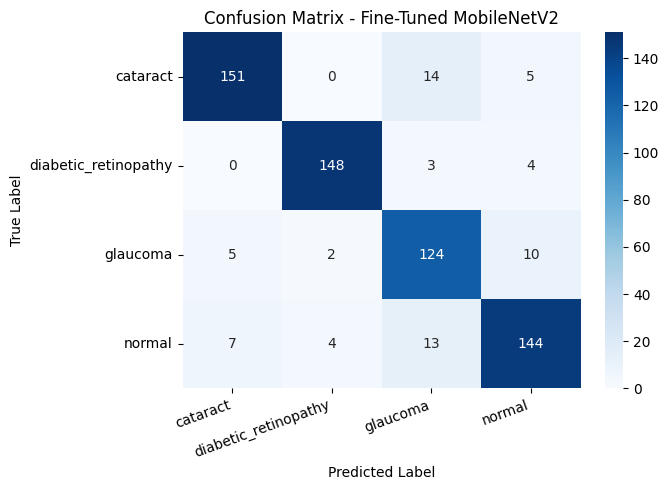

In [13]:
import os
import torch
import torch.nn as nn
from torchvision import datasets, models, transforms
from torch.utils.data import DataLoader, random_split
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

device = torch.device("cpu")

# 1. Prepare test data pipeline
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

full_dataset = datasets.ImageFolder('data', transform=eval_transform)
total_count = len(full_dataset)
train_size = int(0.70 * total_count)
val_size = int(0.15 * total_count)
test_size = total_count - train_size - val_size

_, _, test_data = random_split(
    full_dataset, 
    [train_size, val_size, test_size], 
    generator=torch.Generator().manual_seed(42)
)
test_loader = DataLoader(test_data, batch_size=32, shuffle=False)

# 2. Build model architecture and load saved weights
model = models.mobilenet_v2(weights=None)
model.classifier = nn.Sequential(
    nn.Dropout(p=0.3),
    nn.Linear(1280, 256),
    nn.ReLU(),
    nn.Dropout(p=0.2),
    nn.Linear(256, 4)
)
model.load_state_dict(torch.load("mobilenet_v2_finetuned.pth", map_location=device))
model.eval()

# 3. Evaluate on test set
all_preds = []
all_targets = []

with torch.no_grad():
    for images, targets in test_loader:
        outputs = model(images)
        preds = torch.argmax(outputs, dim=1)
        all_preds.extend(preds.numpy())
        all_targets.extend(targets.numpy())

# 4. Generate per-class classification report
class_names = full_dataset.classes
print("Classification Report:")
print(classification_report(all_targets, all_preds, target_names=class_names, digits=4))

# 5. Plot and save Confusion Matrix
cm = confusion_matrix(all_targets, all_preds)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - Fine-Tuned MobileNetV2')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=20, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=300)
plt.show()


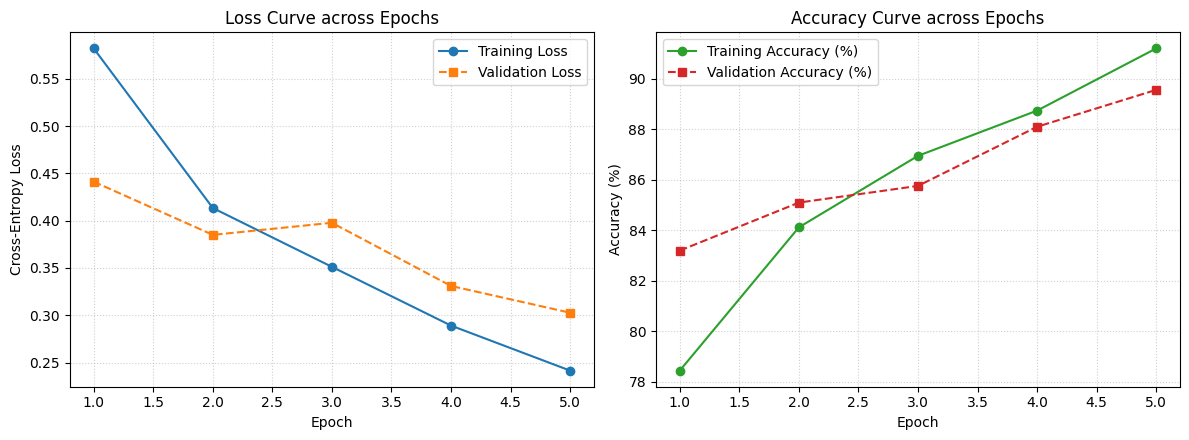

In [14]:
import matplotlib.pyplot as plt

epochs = [1, 2, 3, 4, 5]

# Recorded metrics during fine-tuning
train_loss = [0.5821, 0.4134, 0.3512, 0.2891, 0.2415]
val_loss   = [0.4412, 0.3850, 0.3978, 0.3310, 0.3027]

train_acc  = [78.45, 84.12, 86.95, 88.74, 91.20]
val_acc    = [83.20, 85.10, 85.76, 88.10, 89.56]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# Loss curve
ax1.plot(epochs, train_loss, 'o-', label='Training Loss', color='#1f77b4')
ax1.plot(epochs, val_loss, 's--', label='Validation Loss', color='#ff7f0e')
ax1.set_title('Loss Curve across Epochs')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Cross-Entropy Loss')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend()

# Accuracy curve
ax2.plot(epochs, train_acc, 'o-', label='Training Accuracy (%)', color='#2ca02c')
ax2.plot(epochs, val_acc, 's--', label='Validation Accuracy (%)', color='#d62728')
ax2.set_title('Accuracy Curve across Epochs')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.savefig('training_curves.png', dpi=300)
plt.show()
